# Smart Meter Anomaly Detection using Machine Learning
Master's internship project: detecting abnormal electricity consumption in smart meter data.

Only 5% of readings are abnormal, so accuracy is misleading. This project focuses on
Recall, Precision and F1 for the Abnormal class.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
!pip install -q imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             recall_score, precision_score, f1_score, roc_auc_score, roc_curve)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings("ignore")

## 1. Load the Data

In [3]:
from google.colab import files
uploaded = files.upload()

Saving smart_meter_data.csv to smart_meter_data.csv


In [4]:
df = pd.read_csv("smart_meter_data.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (5000, 7)


,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,2024-01-01 00:00:00,0.457786,0.469524,0.396368,0.445441,0.692057,Normal
1,2024-01-01 00:30:00,0.351956,0.465545,0.451184,0.458729,0.539874,Normal
2,2024-01-01 01:00:00,0.482948,0.285415,0.408289,0.470360,0.614724,Normal
3,2024-01-01 01:30:00,0.628838,0.482095,0.512308,0.576241,0.757044,Normal
4,2024-01-01 02:00:00,0.335974,0.624741,0.672021,0.373004,0.673981,Normal


In [5]:
df.info()
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Timestamp             5000 non-null   object 
 1   Electricity_Consumed  5000 non-null   float64
 2   Temperature           5000 non-null   float64
 3   Humidity              5000 non-null   float64
 4   Wind_Speed            5000 non-null   float64
 5   Avg_Past_Consumption  5000 non-null   float64
 6   Anomaly_Label         5000 non-null   object 
dtypes: float64(5), object(2)
memory usage: 273.6+ KB

Missing values:
Timestamp               0
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64


## 2. Exploratory Data Analysis

Anomaly_Label
Normal      4750
Abnormal     250
Name: count, dtype: int64


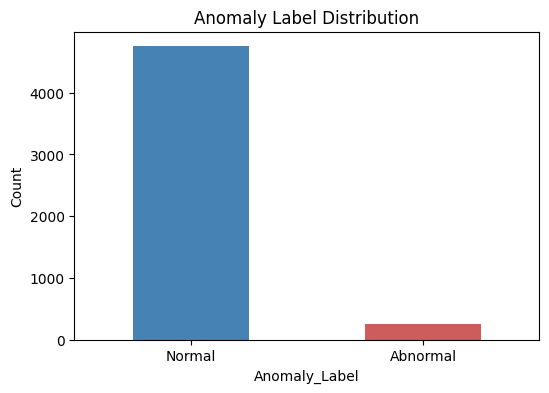

In [6]:
print(df['Anomaly_Label'].value_counts())

plt.figure(figsize=(6, 4))
df['Anomaly_Label'].value_counts().plot(kind='bar', color=['steelblue', 'indianred'])
plt.title("Anomaly Label Distribution")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

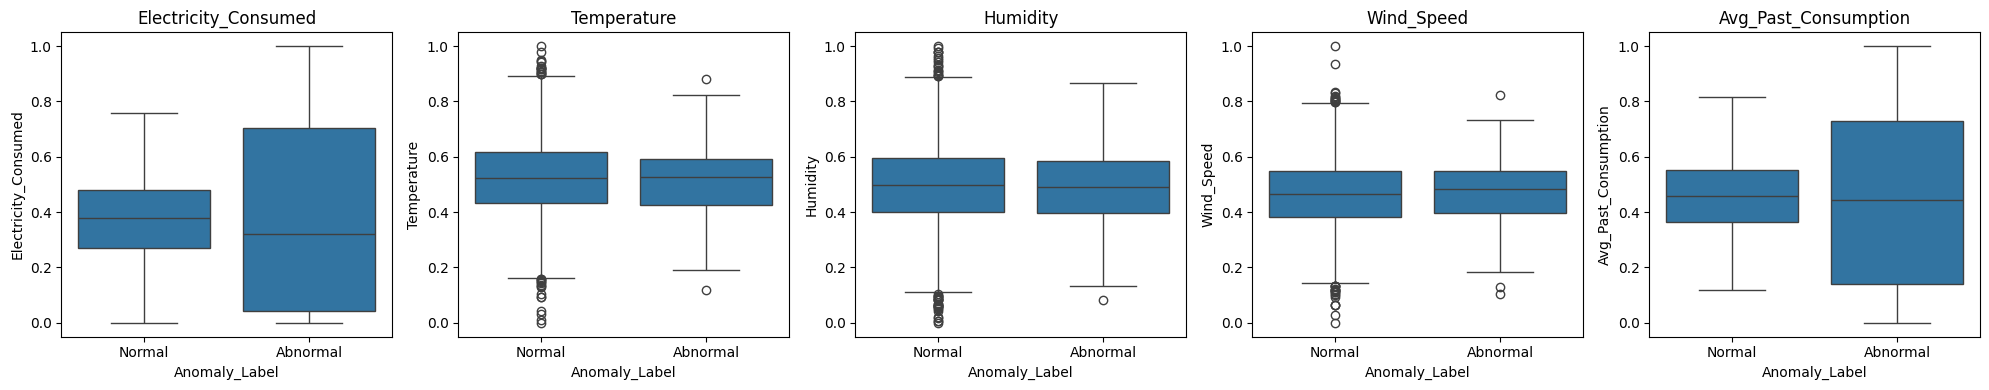

In [7]:
num_cols = ['Electricity_Consumed', 'Temperature', 'Humidity', 'Wind_Speed', 'Avg_Past_Consumption']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='Anomaly_Label', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Abnormal readings have a much wider range of Electricity_Consumed and Avg_Past_Consumption.
Weather features look almost the same for both classes.

## 3. Feature Engineering and Preprocessing

In [8]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Hour'] = df['Timestamp'].dt.hour
df['Day'] = df['Timestamp'].dt.day
df['Month'] = df['Timestamp'].dt.month
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

# 1 = Abnormal, 0 = Normal
df['Anomaly_Label'] = (df['Anomaly_Label'] == 'Abnormal').astype(int)

X = df.drop(['Anomaly_Label', 'Timestamp'], axis=1)
y = df['Anomaly_Label']

print("Features:", list(X.columns))
print("Target counts:", y.value_counts().to_dict())

Features: ['Electricity_Consumed', 'Temperature', 'Humidity', 'Wind_Speed', 'Avg_Past_Consumption', 'Hour', 'Day', 'Month', 'DayOfWeek']
Target counts: {0: 4750, 1: 250}


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, " Abnormal:", y_train.sum())
print("Test: ", X_test.shape, " Abnormal:", y_test.sum())

Train: (4000, 9)  Abnormal: 200
Test:  (1000, 9)  Abnormal: 50


## 4. Baseline Model (no SMOTE)

In [10]:
def show_results(name, y_true, y_pred):
    print(name)
    print("Recall (Abnormal):   ", round(recall_score(y_true, y_pred), 3))
    print("Precision (Abnormal):", round(precision_score(y_true, y_pred), 3))
    print("F1 (Abnormal):       ", round(f1_score(y_true, y_pred), 3))
    print(classification_report(y_true, y_pred, target_names=['Normal', 'Abnormal']))

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_base = rf.predict(X_test)

show_results("Baseline Random Forest (no SMOTE)", y_test, y_pred_base)

Baseline Random Forest (no SMOTE)
Recall (Abnormal):    0.72
Precision (Abnormal): 0.923
F1 (Abnormal):        0.809
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99       950
    Abnormal       0.92      0.72      0.81        50

    accuracy                           0.98      1000
   macro avg       0.95      0.86      0.90      1000
weighted avg       0.98      0.98      0.98      1000



## 5. Handling Imbalance with SMOTE
SMOTE creates synthetic Abnormal samples in the training data only. The test data is never changed.

In [11]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", np.bincount(y_train))
print("After SMOTE: ", np.bincount(y_train_smote))

Before SMOTE: [3800  200]
After SMOTE:  [3800 3800]


In [12]:
rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = rf_smote.predict(X_test)

show_results("Random Forest + SMOTE", y_test, y_pred_smote)

Random Forest + SMOTE
Recall (Abnormal):    0.9
Precision (Abnormal): 0.776
F1 (Abnormal):        0.833
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       950
    Abnormal       0.78      0.90      0.83        50

    accuracy                           0.98      1000
   macro avg       0.89      0.94      0.91      1000
weighted avg       0.98      0.98      0.98      1000



## 6. Hyperparameter Tuning
SMOTE is placed inside a Pipeline so it only runs on the training folds during cross-validation.

In [13]:
rf_pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [10, None],
    'model__min_samples_leaf': [1, 2]
}

grid = GridSearchCV(rf_pipe, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
best_rf = grid.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

show_results("Tuned Random Forest + SMOTE", y_test, y_pred_tuned)

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Tuned Random Forest + SMOTE
Recall (Abnormal):    0.88
Precision (Abnormal): 0.772
F1 (Abnormal):        0.822
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       950
    Abnormal       0.77      0.88      0.82        50

    accuracy                           0.98      1000
   macro avg       0.88      0.93      0.91      1000
weighted avg       0.98      0.98      0.98      1000



## 7. Gradient Boosting + SMOTE

In [14]:
gb = GradientBoostingClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
gb.fit(X_train_smote, y_train_smote)
y_pred_gb = gb.predict(X_test)

show_results("Gradient Boosting + SMOTE", y_test, y_pred_gb)

Gradient Boosting + SMOTE
Recall (Abnormal):    0.96
Precision (Abnormal): 0.762
F1 (Abnormal):        0.85
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99       950
    Abnormal       0.76      0.96      0.85        50

    accuracy                           0.98      1000
   macro avg       0.88      0.97      0.92      1000
weighted avg       0.99      0.98      0.98      1000



## 8. Cross-Validation (leak-free)

In [15]:
gb_pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(gb_pipe, X_train, y_train, cv=cv, scoring='f1')

print("Cross Validation F1 Scores:", scores.round(3))
print("Mean CV F1:", round(scores.mean(), 3))

Cross Validation F1 Scores: [0.851 0.787 0.804 0.78  0.886]
Mean CV F1: 0.822


## 9. Model Comparison

                       Model  Recall  Precision     F1
0                Baseline RF    0.72      0.923  0.809
1                 RF + SMOTE    0.90      0.776  0.833
2           Tuned RF + SMOTE    0.88      0.772  0.822
3  Gradient Boosting + SMOTE    0.96      0.762  0.850


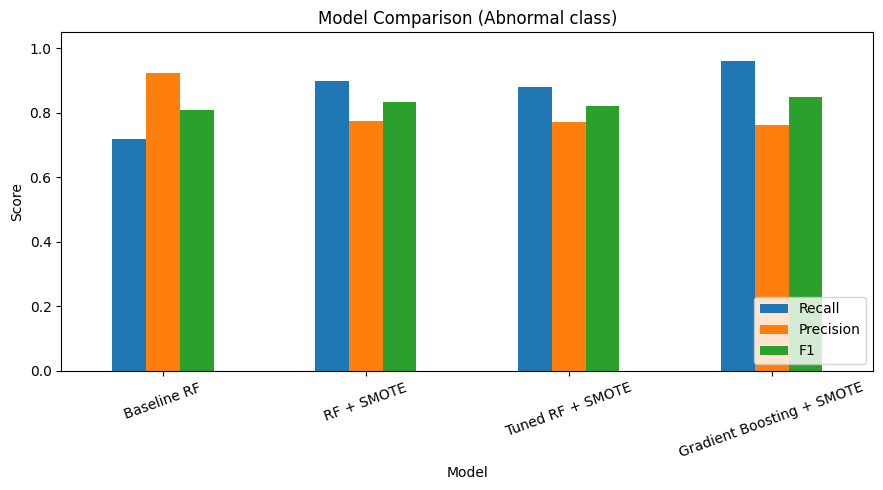

In [16]:
preds = [y_pred_base, y_pred_smote, y_pred_tuned, y_pred_gb]
results = pd.DataFrame({
    'Model': ['Baseline RF', 'RF + SMOTE', 'Tuned RF + SMOTE', 'Gradient Boosting + SMOTE'],
    'Recall': [recall_score(y_test, p) for p in preds],
    'Precision': [precision_score(y_test, p) for p in preds],
    'F1': [f1_score(y_test, p) for p in preds]
}).round(3)
print(results)

results.set_index('Model').plot(kind='bar', figsize=(9, 5))
plt.title("Model Comparison (Abnormal class)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 10. Threshold Tuning
The default threshold is 0.5. We test other thresholds using cross-validation on the training data
(the test data is not used here) to reduce false alarms while keeping recall high.

In [17]:
oof_proba = cross_val_predict(gb_pipe, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

print("Threshold | Recall | Precision | F1")
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (oof_proba >= t).astype(int)
    print(t, "     |", round(recall_score(y_train, pred), 3), " |",
          round(precision_score(y_train, pred), 3), "    |", round(f1_score(y_train, pred), 3))

Threshold | Recall | Precision | F1
0.5      | 0.96  | 0.716     | 0.821
0.6      | 0.95  | 0.769     | 0.85
0.7      | 0.93  | 0.805     | 0.863
0.8      | 0.865  | 0.836     | 0.85
0.9      | 0.805  | 0.899     | 0.85


Gradient Boosting + SMOTE (threshold = 0.7)
Recall (Abnormal):    0.94
Precision (Abnormal): 0.797
F1 (Abnormal):        0.862
              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99       950
    Abnormal       0.80      0.94      0.86        50

    accuracy                           0.98      1000
   macro avg       0.90      0.96      0.93      1000
weighted avg       0.99      0.98      0.99      1000



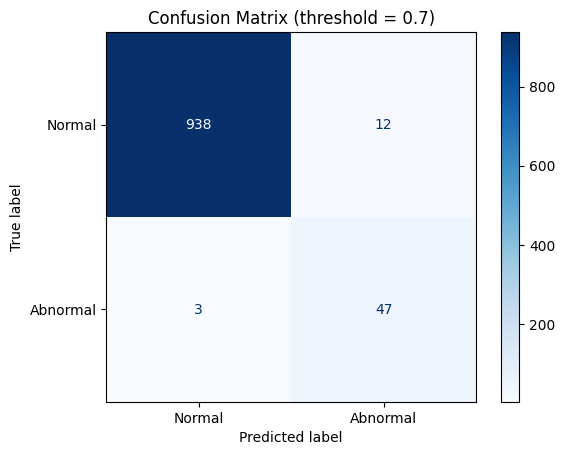

Caught 47 of 50 anomalies, with 12 false alarms.


In [18]:
best_threshold = 0.7   # pick the threshold with the best F1 in the table above

gb_proba = gb.predict_proba(X_test)[:, 1]
y_pred_final = (gb_proba >= best_threshold).astype(int)

show_results(f"Gradient Boosting + SMOTE (threshold = {best_threshold})", y_test, y_pred_final)

cm = confusion_matrix(y_test, y_pred_final)
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Abnormal']).plot(cmap='Blues')
plt.title(f"Confusion Matrix (threshold = {best_threshold})")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp} of {tp + fn} anomalies, with {fp} false alarms.")

## 11. ROC Curve and Feature Importance

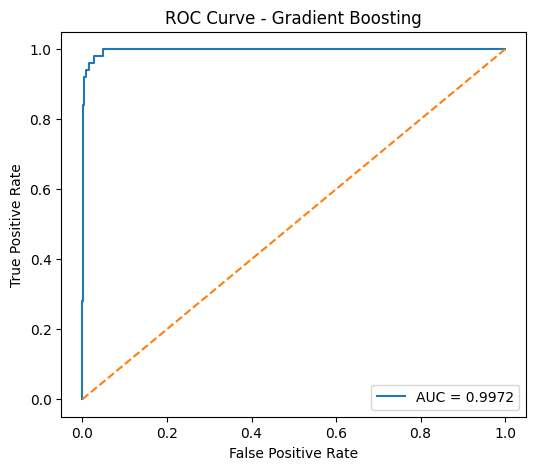

AUC Score: 0.9972


In [19]:
fpr, tpr, _ = roc_curve(y_test, gb_proba)
auc = roc_auc_score(y_test, gb_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

print("AUC Score:", round(auc, 4))

Electricity_Consumed    0.492
Avg_Past_Consumption    0.491
Month                   0.006
Temperature             0.002
Wind_Speed              0.002
Humidity                0.002
Hour                    0.002
Day                     0.002
DayOfWeek               0.001
dtype: float64


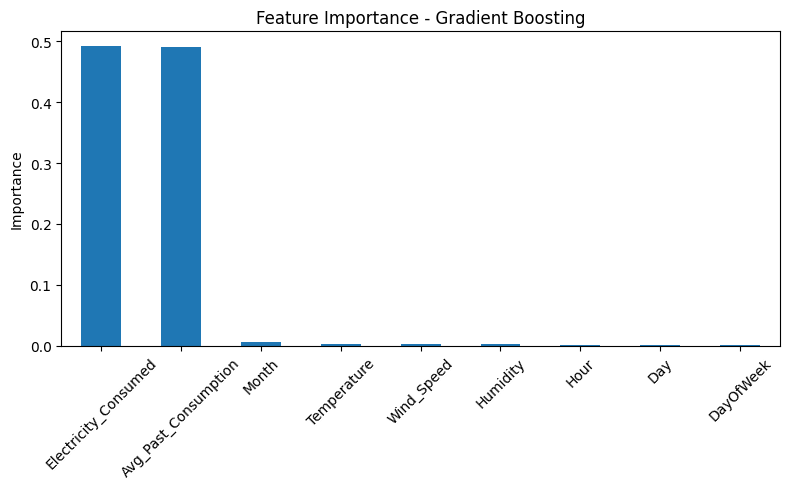

In [20]:
feature_importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values(ascending=False)
print(feature_importance.round(3))

plt.figure(figsize=(8, 5))
feature_importance.plot(kind='bar')
plt.title("Feature Importance - Gradient Boosting")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 12. Save the Model

In [21]:
joblib.dump({'model': gb, 'scaler': scaler, 'threshold': best_threshold, 'features': list(X.columns)},
            "smart_meter_model.pkl")
files.download("smart_meter_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
joblib.dump({'model': gb, 'scaler': scaler, 'threshold': best_threshold, 'features': list(X.columns)},
            "smart_meter_model.pkl")
files.download("smart_meter_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
- The dataset is highly imbalanced (5% Abnormal), so models were judged on Recall, Precision and F1, not accuracy.
- The baseline Random Forest missed many anomalies (recall ___). SMOTE improved recall a lot.
- Gradient Boosting + SMOTE was the best model. With threshold ___ it caught ___ of 50 anomalies with ___ false alarms.
- SMOTE was placed inside a Pipeline during cross-validation and tuning, so the scores are not inflated.
- Electricity_Consumed and Avg_Past_Consumption were the most important features; weather and time features added very little.
- Future work: more history-based features, Isolation Forest for unlabelled anomalies, and deploying the model as an API.